# Wine Quality Prediction
**Objective:** Train and compare three classification models that predict wine quality from physicochemical properties such as acidity, density and alcohol.

**Tech stack:** Python, pandas, numpy, scikit-learn (Random Forest, SGD, SVC), seaborn, matplotlib

> **Note:** `wine_quality.csv` is a practice dataset with the same columns as the UCI Wine Quality data. For your final submission, use the real data from UCI (archive.ics.uci.edu/dataset/186/wine+quality) or Kaggle. The real files use `;` as separator and have spaces in column names, so you may need `pd.read_csv(path, sep=";")` and to rename columns.

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Load data and inspect
_Checklist: structure, class distribution of quality scores_

In [3]:
df = pd.read_csv("wine_quality.csv")
print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum())
df.head()

Shape: (1600, 12)
Nulls: 0


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,8.0547,0.5321,0.2360,5.2522,0.1082,7.4231,41.1268,0.9987,3.2724,0.6381,9.5179,5
1,9.0279,0.5889,0.2856,1.1334,0.0667,5.5569,28.0378,0.9986,3.3187,0.5137,8.9432,5
2,10.0534,0.6086,0.0476,2.4006,0.0432,16.1896,44.9127,0.9972,3.5822,0.8325,10.1268,6
3,10.1692,0.5674,0.3762,1.4310,0.0671,9.3288,30.4794,0.9962,3.2394,0.6606,10.8625,7
4,7.8266,0.3902,0.2036,3.3771,0.0562,15.9255,63.0405,0.9953,3.5261,0.5840,11.6497,5


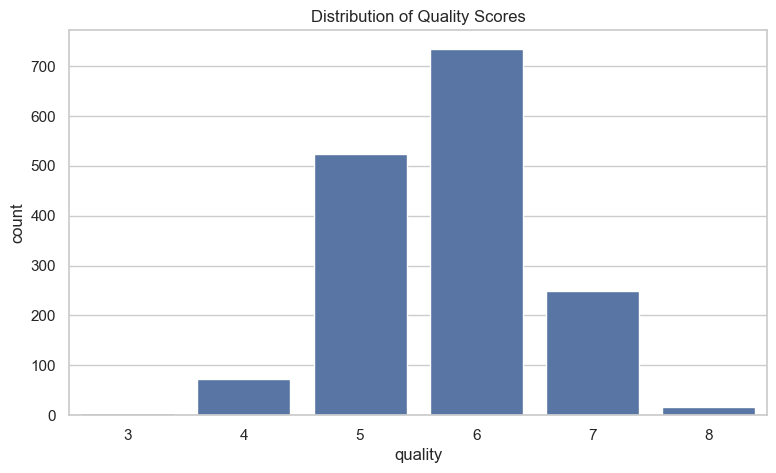

quality
3      5
4     72
5    523
6    735
7    249
8     16
Name: count, dtype: int64


In [4]:
sns.countplot(data=df, x="quality")
plt.title("Distribution of Quality Scores")
plt.show()
print(df["quality"].value_counts().sort_index())

**Observation:** _Write 2-3 sentences about what this output shows._

## 2. EDA
_Checklist: distribution plots for all chemical features; correlation heatmap_

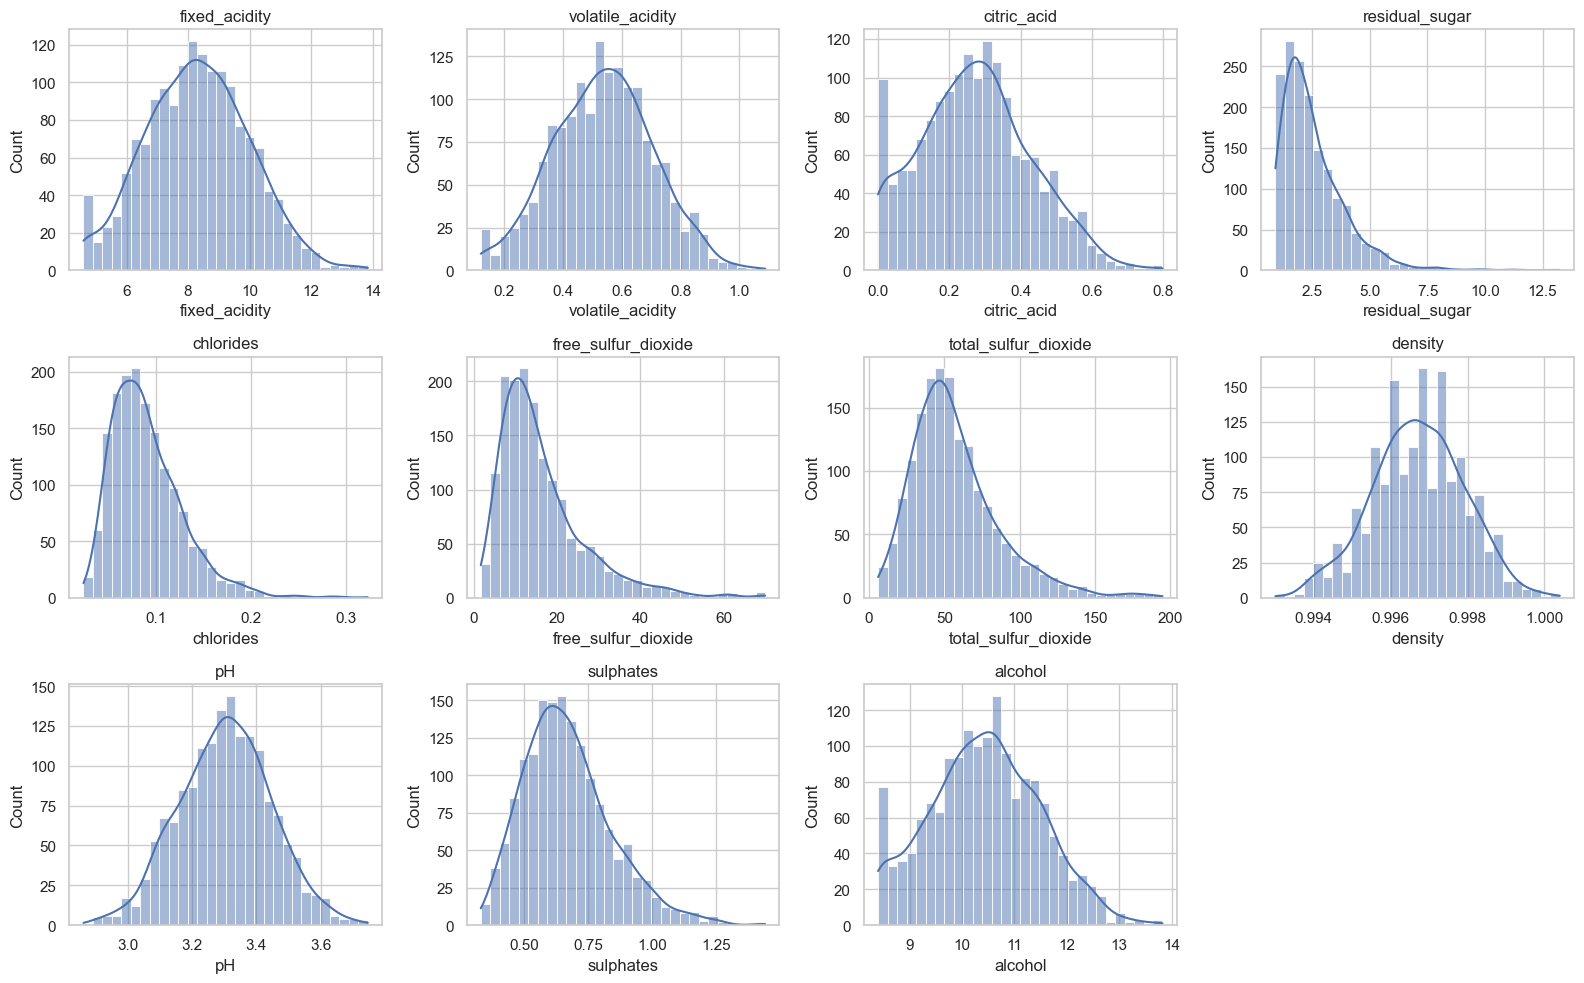

In [5]:
features = df.columns.drop("quality")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observation:** _Which features look skewed? Any with extreme values?_

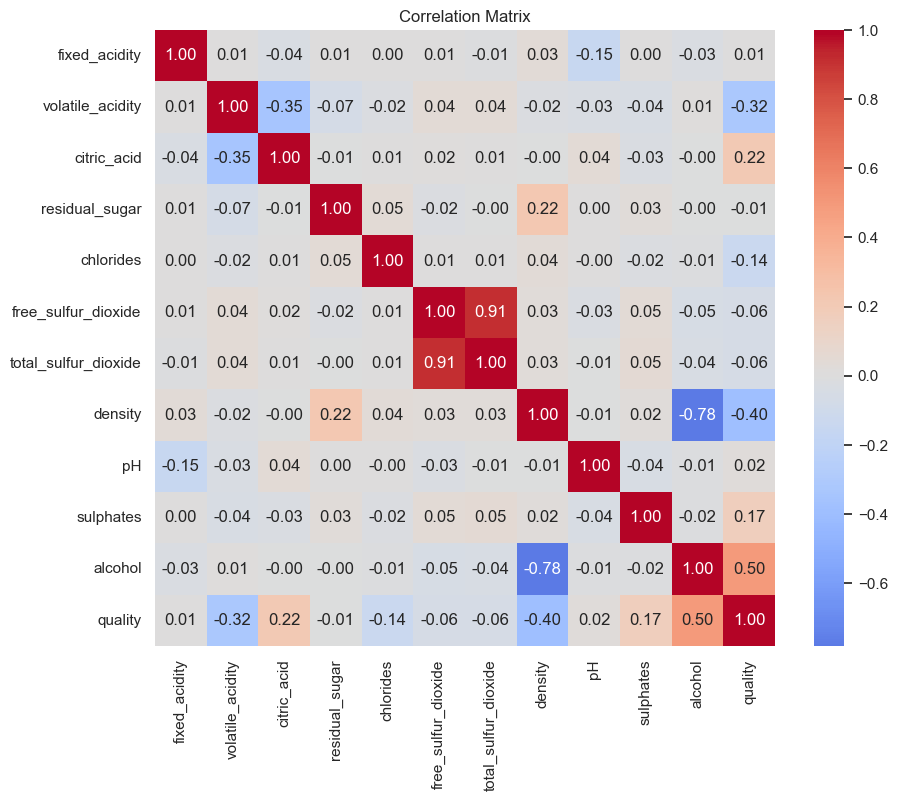

alcohol                 0.50
citric_acid             0.22
sulphates               0.17
pH                      0.02
fixed_acidity           0.01
residual_sugar         -0.01
total_sulfur_dioxide   -0.06
free_sulfur_dioxide    -0.06
chlorides              -0.14
volatile_acidity       -0.32
density                -0.40
Name: quality, dtype: float64


In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()
print(df.corr()["quality"].drop("quality").sort_values(ascending=False).round(2))

**Observation:** _Which features correlate most with quality, positively and negatively?_

## 3. Class imbalance
_Checklist: are some quality scores underrepresented, and how does it affect modelling?_

_Write your discussion here. Think about:_
- _Which scores have very few samples?_
- _Why would a model that always predicts the most common score still get high accuracy?_
- _Why is accuracy alone not enough, and which metrics help?_

## 4. Feature engineering: group the quality scores
_Checklist: bin quality into binary or 3 classes and justify the decision_

In [7]:
def group_quality(q):
    if q <= 4:
        return "low"
    elif q <= 6:
        return "medium"
    return "high"

df["quality_group"] = df["quality"].apply(group_quality)
df["quality_group"].value_counts()

quality_group
medium    1258
high       265
low         77
Name: count, dtype: int64

**Justification:** _Why group the scores? What did you gain and lose? You could also try a binary split (for example good = 7 or higher) and compare. Change `group_quality` to experiment._

## 5. Train/test split with stratification

In [8]:
X = df.drop(columns=["quality", "quality_group"])
y = df["quality_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train class ratios:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class ratios:\n", y_test.value_counts(normalize=True).round(3))

Train class ratios:
 quality_group
medium    0.786
high      0.166
low       0.048
Name: proportion, dtype: float64

Test class ratios:
 quality_group
medium    0.788
high      0.166
low       0.047
Name: proportion, dtype: float64


**Why stratify?** _Check the two tables above. What would go wrong without it for the smallest class?_

## 6. Train the three classifiers
_Checklist: Random Forest, SGD, SVC_

In [9]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SGD": make_pipeline(StandardScaler(), SGDClassifier(random_state=42)),
    "SVC": make_pipeline(StandardScaler(), SVC(random_state=42)),
}

preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    print(f"{name}: trained")

Random Forest: trained
SGD: trained
SVC: trained


**Why the StandardScaler?** _SGD and SVC are sensitive to feature scale, while Random Forest is not. Explain in your own words._

## 7. Evaluate each model
_Checklist: accuracy, classification report, confusion matrix_

In [10]:
labels = ["low", "medium", "high"]

for name, p in preds.items():
    print("=" * 60)
    print(name, "- accuracy:", round(accuracy_score(y_test, p), 3))
    print(classification_report(y_test, p, labels=labels, zero_division=0))

Random Forest - accuracy: 0.8
              precision    recall  f1-score   support

         low       1.00      0.07      0.12        15
      medium       0.81      0.97      0.88       252
        high       0.58      0.21      0.31        53

    accuracy                           0.80       320
   macro avg       0.80      0.41      0.44       320
weighted avg       0.78      0.80      0.75       320

SGD - accuracy: 0.797
              precision    recall  f1-score   support

         low       0.50      0.13      0.21        15
      medium       0.82      0.94      0.88       252
        high       0.56      0.28      0.38        53

    accuracy                           0.80       320
   macro avg       0.63      0.45      0.49       320
weighted avg       0.76      0.80      0.76       320

SVC - accuracy: 0.784
              precision    recall  f1-score   support

         low       0.00      0.00      0.00        15
      medium       0.80      0.98      0.88       252
 

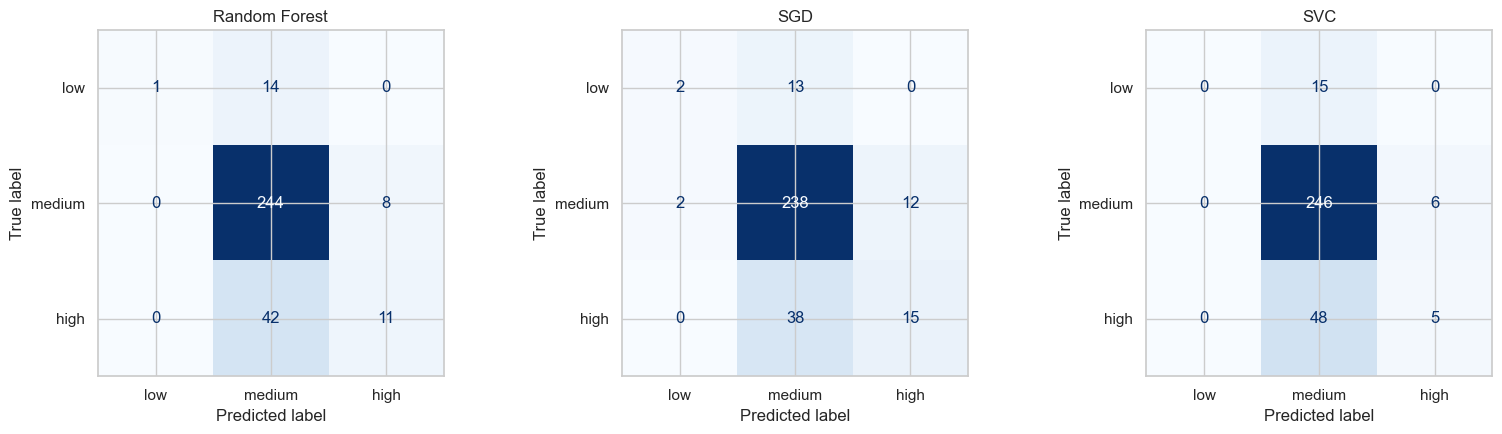

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Observation:** _Which classes does each model struggle with? Look at recall for `low` and `high`._

## 8. Feature importance (Random Forest)

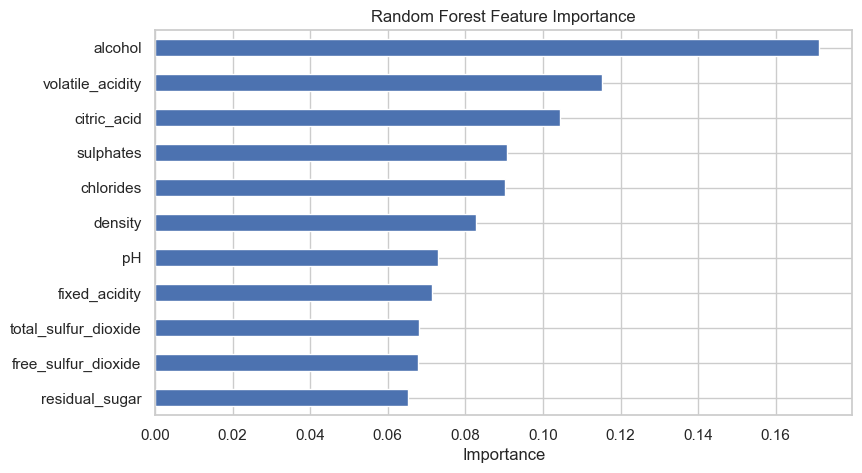

In [12]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

imp.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 9. Comparison table

In [13]:
rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Macro F1": f1_score(y_test, p, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, p, average="weighted", zero_division=0),
    })
comparison = pd.DataFrame(rows).round(3).set_index("Model")
comparison

,Accuracy,Macro F1,Weighted F1
Model,,,
Random Forest,0.800,0.438,0.753
SGD,0.797,0.488,0.765
SVC,0.784,0.344,0.717


**Observation:** _Which model leads on accuracy? Which on macro F1 (which treats each class equally)? Do they agree?_

## 10. Conclusion
_Which model would you deploy and why? Consider accuracy, performance on the rare classes, speed and how easy it is to explain. Also say what you would do to improve results (more data, tuning, resampling...)._